# Natural language processing of clinical data
 ###  Xiaowen Li
 ###  supervisor: Yalu Wen

# step one: prepare data

In [1]:
# set up notebook
from __future__ import division
from pandas import read_excel
import pandas as pd
import numpy as np
import nltk, re, pprint
import matplotlib.pyplot as plt

# read in the clinical data set.
dfRaw = pd.read_excel('/Users/lixiaowen/Desktop/UOA_dissertation/Data/dataset.xlsx')
data = pd.DataFrame(dfRaw)
data.head()

,Comorbidity,SNOMED,Coding,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,Comorbidity,0,Comorbidity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,None,0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Multiple recent GAs OK: vancomycin and ceftria...,0,"vancomycin, ceftriaxone",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Type 2 DM: on GIK infusion (also on metformin),0,Type 2 diabetes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"Hypertension, dyslipidaemia: cilazapril, aspir...",0,"Hypertension, dyslipidemia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# select the columns we need: 'Comorbidity' and 'Coding'.
df = data.copy()
df = df[['Comorbidity', 'Coding']]
len(df)

303341

## Data cleaning

In [3]:
# check whether there exists in 'Coding' miising data
print(df.Coding.isnull().sum())
print(df.Coding.isnull().sum()/len(df.Coding))

2606
0.008590991656254841


the missing values account for around 1.76% and 0.92% in these two features. We need to label smoker, exsmoker and nonsmoker accding to 'Coding' to obtain the output. It includes missing values and 0 from which we could not determine the patient is a smoker or not. Hence we replace it with white space and remove these records. Hence, we will preprocess the missing values first.

In [4]:
import string
df.dropna(inplace=True)
df = df[df.Coding != ' ']
df = df[df.Coding != 0]
len(df)

295408

### Label encoding --- the 'smoker', 'exsmoker' and 'nonsmoker'
we are going to classifiy a patient into smoker, ex-smoker or non-smoker. Therefore, we need to create a variable with output label(1= smoker, 2 = ex-smoker, 0 = nonsmoker) according to the variable 'Coding'. 

First, we normalize the 'Coding' column.

     converting all letters to lower case
     removing numbers
     removing punctuations, accent marks and other diacritics
     removing white spaces
     lemmatize words.

In [5]:
# normalize 'Coding' notes.
df_clean = df.copy()

def text_clean(text):
    '''
    replace punctuations and number with spaces.
    remove anything but characters and spaces.
    convert text into lower case.
    '''
    punc_list = string.punctuation + '0123456789'
    t = str.maketrans(dict.fromkeys(punc_list, ''))
    text = text.str.lower().str.translate(t)
    return text

df_clean.Coding = text_clean(df_clean.Coding)

# drop NA
df_clean = df_clean.dropna()

len(df_clean)


295344

the'non-smoker' and 'ex-smoker' have already convert to 'nonsmoker' and 'exsmoker'. 
Next, I will try to remove the space of 'non smoker' and 'ex smoker'.
convert 'quit smoking', 'stopped smoking', 'not smoking' ,'previous smoking', 'gve up smoking' and 'stop smoking' to 'exsmoker'

For easier, we tokenize the sentences first and lemmatize the 'Coding' first. After lemmatization, the word 'smoking', 'smokes', 'smoked' become 'smoke', etc. Finally, join them together.

### tokenize and lemmatize 'Coding'

In [6]:
from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer 
from nltk.tag import pos_tag

#tokenize text
df_clean.Coding = df_clean.Coding.apply(word_tokenize)

#lemmatize Words
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    return [lemmatizer.lemmatize(w, pos = "v") for w in text]

# Lemmatize list of words and join
df_clean.Coding  = df_clean.Coding.apply(lemmatize_text)

#join the words in 'Coding'
df_clean.Coding =df_clean.Coding.str.join(' ')

In [7]:
#replace word list.
word_list_non = ['deny smoke', 'non smoker', 'never smoke']
df_clean.Coding = df_clean.Coding.str.replace('|'.join(word_list_non), 'nonsmoker')
df_clean.Coding = df_clean.Coding.str.replace('smokin', 'smoke')
df_clean.Coding = df_clean.Coding.str.replace('smokeer', 'smoker')

word_list_ex = ['quit smoke', 'stop smoke', 'not smoke','previous smoke', 
            'give up smoke', 'stop smoke', 'ex heavy smoker', 'prev heavy smoker',
            'smoker exsmoker', 'ex smoker', 'previous heavy smoker', 
            'smoker stop','ex smoke','prev smoker','previous heavy smoke']
df_clean.Coding = df_clean.Coding.str.replace("|".join(word_list_ex), 'exsmoker')


# convert 'smokes', individual 'smoking' to smoker.
df_clean.Coding = df_clean.Coding.str.replace(r'\bsmoke\b', 'smoker')

A new variable called 'SmokeOrNot ', we labeled the smoker as 'smoker', labeled ex smoker as 'exsmoker' and others as 'nonsmoker'. 
Another variable called output_label is created with the output label (2 = Exsmoker, 1 = Smoker, 0 = Nonsmoker)

If the notes in 'Coding' include smoker, output_label = 1, SmokeOrNot = smoker
If the notes in 'Coding' include exsmoker, output_label = 2, SmokeOrNot = exsmoker
If the notes in 'Coding' include smoker, output_label = 0, SmokeOrNot = nonsmoker

In [8]:
# we labeled the smoker as 'Smoker', labeled ex smoker as 'Exsmoker' and others as 'Nonsmoker'.
conditions = [
    (df_clean.Coding.str.contains(r'\bexsmoker\b')),
    (df_clean.Coding.str.contains(r'\bsmoker\b'))]
choices = ['Exsmoker','Smoker']

df_clean['SmokeOrNot'] = np.select(conditions, choices, default = 'Nonsmoker')

# Create a varibale 'output_label' with (2 = Exsmoker, 1 = Smoker, 0 = Nonsmoker)
'''
conditions1 = [
    (df_clean['SmokeOrNot'] == 'Nonsmoker'),
    (df_clean['SmokeOrNot'] =='Smoker')]
choices1 = [0, 1]

df_clean['output_label'] = np.select(conditions1, choices1, default = 2)
'''
mappings = {'Smoker': 1, 'Exsmoker': 2, 'Nonsmoker': 0}
df_clean['output_label'] = df_clean['SmokeOrNot'].map(mappings)

#count the number of each type.
print(len(df_clean))
print(df_clean.SmokeOrNot.value_counts())

295344
Nonsmoker    289581
Smoker         3847
Exsmoker       1916
Name: SmokeOrNot, dtype: int64


In [9]:
df_clean.head()

,Comorbidity,Coding,SmokeOrNot,output_label
0,Comorbidity,comorbidity,Nonsmoker,0
1,None,none,Nonsmoker,0
2,Multiple recent GAs OK: vancomycin and ceftria...,vancomycin ceftriaxone,Nonsmoker,0
3,Type 2 DM: on GIK infusion (also on metformin),type diabetes,Nonsmoker,0
4,"Hypertension, dyslipidaemia: cilazapril, aspir...",hypertension dyslipidemia,Nonsmoker,0


# partition training, testing and validation sets

In order to avoid overfitting, Cross validation will be tried. We would like to partition the original dataset into three parts, training, validation and testing set. 

10% of the dataset will be drawn randomly from the original dataset which would keep unchange and used to test and compare different models. Others will be split into 10 kolds and to apply cross validation method.

the random_state = 42

In [192]:
# shuffle the samples
df_clean_random = df_clean.sample(n = len(df_clean), random_state = 42)
df_clean_random = df_clean_random.reset_index(drop = True)
# Save 20% of the data as the test data
# use the rest of the data as train and validation set.
data_test = df_clean_random.sample(frac=0.20,random_state = 42)
data_train_valid = df_clean_random.drop(data_test.index).drop(['Coding'], axis= 1)

In [193]:
data_train_valid[:10]

,Comorbidity,SmokeOrNot,output_label
1,Lower lip- herpes simplex,Nonsmoker,0
2,3. Peripheral neuropathy (numb feet) - takes ...,Nonsmoker,0
3,Obesity BM! 42,Nonsmoker,0
4,7. Severe OSA,Nonsmoker,0
5,LBBB. Denies sx of IHD,Nonsmoker,0
7,Heavy ETOH and smoking,Smoker,1
8,nil orthopnoea. Denies angina.,Nonsmoker,0
9,lungs great now,Nonsmoker,0
10,4. increased BMI,Nonsmoker,0
13,"laceration neck with razor blade, self harm",Nonsmoker,0


In [196]:
print(sum(data_test.output_label == 0))
print(sum(data_test.output_label == 1))
print(sum(data_test.output_label == 2))

57902
774
393


# Step two:  create the bag-of-words of 'Comorbidity' notes


First, we need to preprocess the Comorbidity notes and create the Bag-of-Words(BOW).

The main idea is to break up each text into individual words and then count the frequency of each word occurs. 

Now, we need to preprocess the 'Comorbidity' notes. The steps are similar as we done to preprocess the 'Coding'.

Preprocess the 'Comorbidity' notes

    converting all letters to lower case
    removing numbers (replace numbers with whitespace)
    removing punctuations, accent marks and other diacritics (replace them with spaces)
    removing white spaces

Then, the notes are tokenized by tokenizer (word_tokenize( )), remove stop words and count the frequency using TfidfVectorizer. We could notice that there are a lot of words occuring most frequently but giving little information, such as words 'the', 'and', 'of', 'to', etc. We call them stop words. We need to remove stop words, sparse terms, and particular words.


## 'Comorbidity' notes cleaning and normalization

In [197]:
data_train_valid_clean = data_train_valid.copy()

# use text_clean() function we defined to clean data.
data_train_valid_clean.Comorbidity = text_clean(data_train_valid_clean.Comorbidity)

## 'Comorbidity' notes tokenization

In [198]:
# tokenize Comorbidity.
data_train_valid_clean['tokens_Comorbidity'] = data_train_valid_clean.Comorbidity.apply(word_tokenize) 
data_train_valid_clean.head()

,Comorbidity,SmokeOrNot,output_label,tokens_Comorbidity
1,lower lip herpes simplex,Nonsmoker,0,"[lower, lip, herpes, simplex]"
2,peripheral neuropathy numb feet takes amitr...,Nonsmoker,0,"[peripheral, neuropathy, numb, feet, takes, am..."
3,obesity bm,Nonsmoker,0,"[obesity, bm]"
4,severe osa,Nonsmoker,0,"[severe, osa]"
5,lbbb denies sx of ihd,Nonsmoker,0,"[lbbb, denies, sx, of, ihd]"


In [199]:
# create a new variable 'lemmatized_output' to store the lemmatized notes.
data_train_valid_clean['lemmatized_tokens'] = data_train_valid_clean.tokens_Comorbidity.apply(lemmatize_text)

data_train_valid_clean.head()

,Comorbidity,SmokeOrNot,output_label,tokens_Comorbidity,lemmatized_tokens
1,lower lip herpes simplex,Nonsmoker,0,"[lower, lip, herpes, simplex]","[lower, lip, herpes, simplex]"
2,peripheral neuropathy numb feet takes amitr...,Nonsmoker,0,"[peripheral, neuropathy, numb, feet, takes, am...","[peripheral, neuropathy, numb, feet, take, ami..."
3,obesity bm,Nonsmoker,0,"[obesity, bm]","[obesity, bm]"
4,severe osa,Nonsmoker,0,"[severe, osa]","[severe, osa]"
5,lbbb denies sx of ihd,Nonsmoker,0,"[lbbb, denies, sx, of, ihd]","[lbbb, deny, sx, of, ihd]"


## convert words into number vectors and count frequency
### conpare the BOW including stop words  and  BOW without stop words

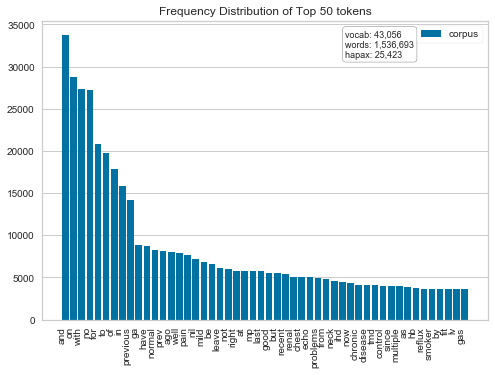

In [200]:
from yellowbrick.text import FreqDistVisualizer
from sklearn.feature_extraction.text import CountVectorizer

data_train_valid_clean['final_Comorbidity'] = [' '.join(x) 
                                               for x in data_train_valid_clean['lemmatized_tokens'].values]
vectorizer = CountVectorizer()
docs       = vectorizer.fit_transform(data_train_valid_clean.final_Comorbidity)
features   = vectorizer.get_feature_names()

visualizer = FreqDistVisualizer(features = features, n=50, orient='v')
visualizer.fit(docs)
visualizer.poof()

There are 46238 words in BOW. We can see that words such as 'and', 'on', 'with'.. giving no valuable information for classification

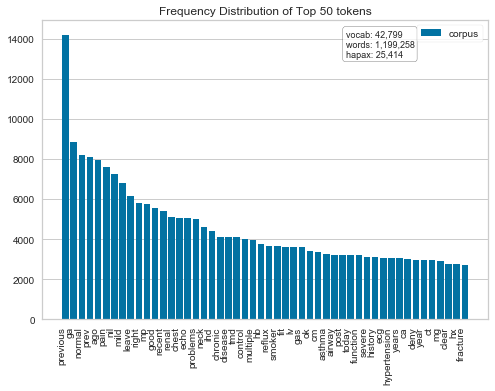

In [201]:
vectorizer = CountVectorizer(stop_words = 'english')
docs       = vectorizer.fit_transform(data_train_valid_clean.final_Comorbidity)
features   = vectorizer.get_feature_names()

visualizer = FreqDistVisualizer(features = features, n=50, orient='v')
visualizer.fit(docs)
visualizer.poof()

There are 45979 words in BOW. We can see that words such as 'and', 'on', 'with' have already been removed. the rest of words are more informative. It is better to remove stop words.

### the most important words in each class
####  the most important words for ' Nonsmoker'

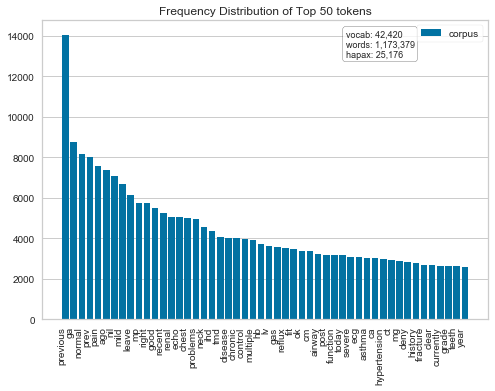

In [202]:
from collections import defaultdict

smokerornot = defaultdict(list)
for text, label in zip(data_train_valid_clean.final_Comorbidity, data_train_valid_clean.SmokeOrNot):
    smokerornot[label].append(text)
vectorizer = CountVectorizer(stop_words = 'english')
docs       = vectorizer.fit_transform(text for text in smokerornot['Nonsmoker'])
features   = vectorizer.get_feature_names()

visualizer = FreqDistVisualizer(features = features, n=50, orient='v')
visualizer.fit(docs)
visualizer.poof()

####  the most important words for 'exsmoker'

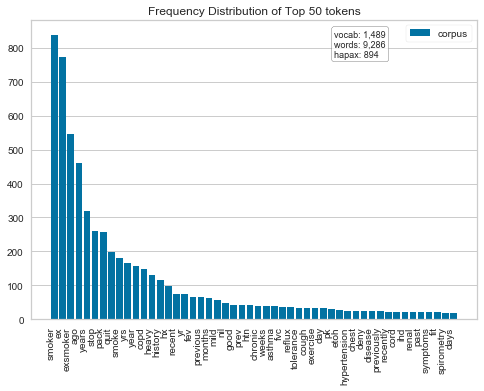

In [203]:
docs       = vectorizer.fit_transform(text for text in smokerornot['Exsmoker'])
features   = vectorizer.get_feature_names()

visualizer = FreqDistVisualizer(features = features, n=50, orient='v')
visualizer.fit(docs)
visualizer.poof()

####  the most important words for 'Smoker'

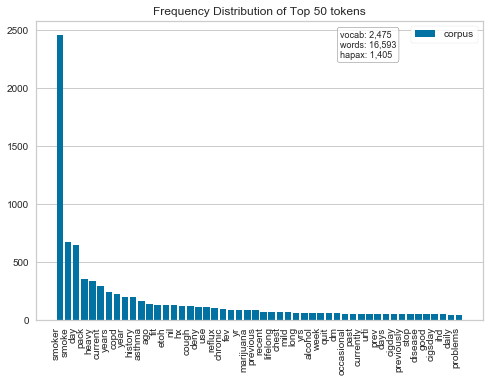

In [204]:
docs       = vectorizer.fit_transform(text for text in smokerornot['Smoker'])
features   = vectorizer.get_feature_names()

visualizer = FreqDistVisualizer(features = features, n=50, orient='v')
visualizer.fit(docs)
visualizer.poof()

the most 50 frequent words of each class are shown in above plots.

# Model assessment

## Confusion-Matrix
With imbalanced classes, it’s easy to get a high accuracy without actually making useful predictions. So, accuracy as an evaluation metrics makes sense only if the class labels are uniformly distributed. In case of imbalanced classes confusion-matrix is good technique to summarizing the performance of a classification algorithm.
Confusion Matrix is a performance measurement for a classification algorithm where output can be two or more classes.

## precision

## recall

## F-score

## Log loss

## kappa

## AUC

## ROC

## AUC-ROC Curves

## Precision-Recall Curves
Precision-Recall is a useful measure of success of prediction when the classes are very imbalanced. Precision is a measure of the ability of a classification model to identify only the relevant data points, while recall is a measure of the ability of a model to find all the relevant cases within a dataset.
The precision-recall curve shows the trade-off between precision and recall for different threshold. A high area under the curve represents both high recall and high precision, where high precision relates to a low false positive rate, and high recall relates to a low false negative rate.
High scores for both precision and recall show that the classifier is returning accurate results (precision), as well as returning a majority of all positive results (recall). An ideal system with high precision and high recall will return many results, with all results labeled correctly.
Below is a precision-recall plot for 20 News groups dataset using scikit-learn.


# Step Build a simple model ( Logistic Regression ) & Train Model

Before applying other more complex models such as CNN, LSTMs, BERT etc, I will use logistic regression to fit the original training dataset and resampled training set with different resampling methods. Then, comparing the AUC, precision ,recall, F score to determine which training set would be chosen to used for other models.

In order to avoid the overfitting, 10-fold cross validation is applied to split the data into training set and validation set. Validation sets are used to tune the parameter. Finally, the model will be applied to test set. 

## the original dataset to build LR

### hyperparamater determination

before using the LR, some tuning parameters need to be determined. a plot of the auc against the C and max_feature will be plotted to explore how the hyperparameters affect results. But in order to reduce the running time In this section, I split the data_train_valid_clean set into training (80%) and validation (20%) sets. And draw the plots.

Then, a grid-search will be applied to select the best parameters.

#### determination of C of LR

In [205]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Save 20% of the data as validation data 
valid = data_train_valid_clean.sample(frac=0.20,random_state=42)
train = data_train_valid_clean.drop(valid.index)

tfidf = TfidfVectorizer(max_features = 10000, 
                       stop_words = 'english')

X_train_tf = tfidf.fit_transform(train.final_Comorbidity.values)
y_train = train.output_label

X_valid_tf = tfidf.fit_transform(valid.final_Comorbidity.values)
y_valid = valid.output_label

X_test = data_test.Comorbidity
y_test = data_test.output_label

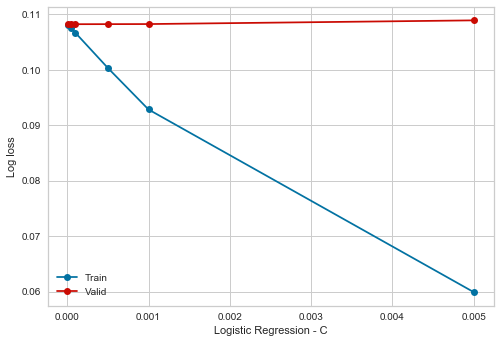

In [206]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
np.random.seed(0)

Cs = [0.00001, 0.00005, 0.0001, 0.0005, 0.0010, 0.0050]
train_logloss = np.zeros(len(Cs))
valid_logloss = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
   
    # logistic regression
    clf = LogisticRegression(C = C, random_state = 42,
                             multi_class = 'multinomial', solver = 'lbfgs')
    clf.fit(X_train_tf, y_train)

    model = clf
    y_train_preds = model.predict_proba(X_train_tf)
    y_valid_preds = model.predict_proba(X_valid_tf)
    logloss_train = log_loss(y_train, y_train_preds)
    logloss_valid = log_loss(y_valid, y_valid_preds)
    train_logloss[ii] = logloss_train
    valid_logloss[ii] = logloss_valid
    
plt.plot(Cs, train_logloss,'bo-', label ='Train')
plt.plot(Cs, valid_logloss, 'ro-', label='Valid')
plt.legend()
plt.xlabel('Logistic Regression - C')
plt.ylabel('Log loss')
plt.show()

#### determination of max_features

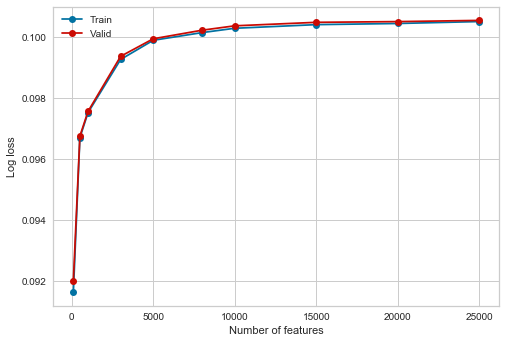

In [222]:
num_features = [100, 500, 1000, 3000, 5000, 8000, 10000, 15000, 20000, 25000]
train_logloss = np.zeros(len(num_features))
valid_logloss = np.zeros(len(num_features))

for ii in range(len(num_features)):
    max_features = num_features[ii]
    tfidf = TfidfVectorizer(lowercase = True, max_features = max_features,
                            stop_words = 'english')

    tfidf.fit(train.final_Comorbidity.values)

    X_train_tf = tfidf.transform(train.final_Comorbidity.values)
    X_valid_tf = tfidf.transform(valid.final_Comorbidity.values)
    y_train = train.output_label
    y_valid = valid.output_label
    
    clf = LogisticRegression(C = 0.0005, random_state = 42, 
                             multi_class = 'multinomial',solver='lbfgs')
    clf.fit(X_train_tf, y_train)

    model = clf
    y_train_preds = model.predict_proba(X_train_tf)
    y_valid_preds = model.predict_proba(X_valid_tf)
    logloss_train = log_loss(y_train, y_train_preds)
    logloss_valid = log_loss(y_valid, y_valid_preds)
    train_logloss[ii] = logloss_train
    valid_logloss[ii] = logloss_valid
    
plt.plot(num_features, train_logloss,'bo-', label ='Train')
plt.plot(num_features, valid_logloss, 'ro-', label='Valid')
plt.legend()
plt.xlabel('Number of features')
plt.ylabel('Log loss')
plt.show()

We can see that with the increase of C, the log loss decreases rapidly which causing the model to overfit. As for the number of features, the performance of the model becomes worse and worse. Hence, I select max_feature = 10000 and C= 0.0005.

### gridsearchcv 
then i use gridsearchcv to determine the best parameters.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV

X_train_valid = data_train_valid_clean.final_Comorbidity
y_train_valid = data_train_valid_clean.output_label

tfidf = TfidfVectorizer(strip_accents=None, 
                        lowercase=False, preprocessor=None)

param_grid = [{'tfidf__ngram_range': [(1, 1)],
               'tfidf__max_features': [5000,10000, 15000],
               'clf__C': [0.00005, 0.0001, 0.0003,0.001, 0.003]},
              {'tfidf__ngram_range': [(1, 1)],
               'tfidf__use_idf':[False],
               'tfidf__norm':[None],
               'clf__C': [0.00005, 0.0001, 0.0003, 0.001],
               'tfidf__max_features': [500, 1000, 3000, 5000,10000, 15000]}
             ]

lr_tfidf = Pipeline([('tfidf', tfidf),
                     ('clf', LogisticRegression(random_state= 42, multi_class = 'multinomial',solver='lbfgs'))])

gs_lr_tfidf = GridSearchCV(lr_tfidf, param_grid, scoring= "neg_log_loss",
                           cv = 5, verbose = 1, n_jobs=-1)


In [ ]:
gs_lr_tfidf.fit(X_train_valid, y_train_valid)

In [597]:
gs_lr_tfidf.best_params_

{'clf__C': 0.003, 'tfidf__max_features': 500, 'tfidf__ngram_range': (1, 1)}

In [599]:
gs_lr_tfidf.best_score_

-0.0841723809507916

In [600]:
clf = gs_lr_tfidf.best_estimator_
clf.score(X_test, y_test)

0.9790411051669262

## logistic regression with 5-fold cross validation 

In [212]:
X_train_valid = data_train_valid_clean.final_Comorbidity.values.astype('U')
y_train_valid = data_train_valid_clean.output_label.values.astype('U')

In [292]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, log_loss, cohen_kappa_score
from sklearn.metrics import confusion_matrix


# set max_features= 10000, C= 0.0005.
tvec = TfidfVectorizer(stop_words = 'english', max_features=10000, ngram_range=(1, 3))
lr = LogisticRegression(C = 0.0005, random_state = 42, 
                        multi_class = 'multinomial',solver='lbfgs')

def lr_cv(splits, X, Y, pipeline, average_method):
    
    kfold = StratifiedKFold(n_splits = splits, shuffle = True, random_state= 42)
    accuracy = []
    precision = []
    recall = []
    f1 = []
    kappa = []
    for train, test in kfold.split(X, Y):
        lr_fit = pipeline.fit(X[train], Y[train])
        prediction = lr_fit.predict(X[test])
        scores = lr_fit.score(X[test],Y[test])
        
        accuracy.append(scores * 100)
        precision.append(precision_score(Y[test], prediction, average=average_method)*100)
        print('              nonsmoker    smoker     exsmoker')
        print('precision:', precision_score(Y[test], prediction, average=None))
        recall.append(recall_score(Y[test], prediction, average=average_method)*100)
        print('recall:   ',recall_score(Y[test], prediction, average= None))
        f1.append(f1_score(Y[test], prediction, average=average_method)*100)
        print('f1 score: ',f1_score(Y[test], prediction, average= None))
        kappa.append(cohen_kappa_score(Y[test], prediction)*100)
        print('kappa: ',cohen_kappa_score(Y[test], prediction))
        
        print('-'*50)

    print("accuracy: %.2f%% (+/- %.2f%%)" % (np.mean(accuracy), np.std(accuracy)))
    print("precision: %.2f%% (+/- %.2f%%)" % (np.mean(precision), np.std(precision)))
    print("recall: %.2f%% (+/- %.2f%%)" % (np.mean(recall), np.std(recall)))
    print("f1 score: %.2f%% (+/- %.2f%%)" % (np.mean(f1), np.std(f1)))
    print("kappa: %.2f%% (+/- %.2f%%)" % (np.mean(kappa), np.std(kappa)))
    

In [289]:
from sklearn.pipeline import Pipeline

original_pipeline = Pipeline([
    ('vectorizer', tvec),
    ('clf', lr)
])

In [293]:
lr_cv(5, X_train_valid, y_train_valid, original_pipeline, 'macro')

/Users/lixiaowen/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


              nonsmoker    smoker     exsmoker
precision: [0.98053157 0.         0.        ]
recall:    [1. 0. 0.]


/Users/lixiaowen/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


f1 score:  [0.9901701 0.        0.       ]
kappa:  0.0
--------------------------------------------------


/Users/lixiaowen/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


              nonsmoker    smoker     exsmoker
precision: [0.98053157 0.         0.        ]
recall:    [1. 0. 0.]


... (10 outputs left out)

/Users/lixiaowen/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


              nonsmoker    smoker     exsmoker
precision: [0.98057266 0.         0.        ]
recall:    [1. 0. 0.]


/Users/lixiaowen/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


f1 score:  [0.99019105 0.         0.        ]
kappa:  0.0
--------------------------------------------------
accuracy: 98.05% (+/- 0.00%)
precision: 32.68% (+/- 0.00%)
recall: 33.33% (+/- 0.00%)
f1 score: 33.01% (+/- 0.00%)
kappa: 0.00% (+/- 0.00%)


# Step four: improve the performance 

## Sampling-based approaches
The basic idea of sampling methods is to simply adjust the proportion of the classes in order to increase the weight of the minority class observations within the model.

The sampling-based approaches can be divided further into three different categories:

1. Undersampling methods: Elimination of randomly chosen cases of the majority class to decrease their effect on the classifier. All cases of the minority class are kept. 
   backwards: 

2. Oversampling methods: Generation of additional cases (copies, artificial observations) of the minority class to increase their effect on the classifier. All cases of the majority class are kept.

3. Hybrid methods: Mixture of under- and oversampling strategies.

All these methods directly access the underlying data and “rearrange” it. In this way the sampling is done as part of the preprocesssing and can therefore be combined with every appropriate classifier.

Considering the disadvantages of original undersampling and oversampling method, I tried three methods Undersampling, ADA-SYN and SMOTEBoost (Intergration of SMOTE and Adaboost) 
and use a base line method Multinomial Logistic Regression method to compare the of performance oversampled, downsampled, original dataset.

I will use 5-Fold Cross Validation. I partition the data into three parts: training, validation, test. The test set have already splited before. Then, the rest of the data will be split into 5 folds to conduct cross validation process. 







## a.  Oversampling the minority classes

In [216]:
!pip install imblearn

RandomOverSampler
SMOTE (Synthetic Minority Over-Sampling Technique)
ADASYN

##  RandomOverSampler
Random over-sampling is simply a process of repeating some samples of the minority class and balance the number of samples between classes in the dataset. 

In [276]:
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler


ROS_pipeline = make_pipeline(tvec, RandomOverSampler(random_state=42),lr)
SMOTE_pipeline = make_pipeline(tvec, SMOTE(random_state=42),lr)

In [294]:
lr_cv(5, X_train_valid, y_train_valid, ROS_pipeline, 'macro')

              nonsmoker    smoker     exsmoker
precision: [0.99896216 0.88325653 0.77464789]
recall:    [0.99710808 0.93495935 0.90163934]
f1 score:  [0.99803426 0.90837283 0.83333333]
kappa:  0.8923852692877732
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99913525 0.89612403 0.8028169 ]
recall:    [0.99741022 0.9398374  0.93442623]
f1 score:  [0.99827199 0.91746032 0.86363636]
kappa:  0.9063415827077448
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99894104 0.87556904 0.83384615]
recall:    [0.99756129 0.93821138 0.88852459]
f1 score:  [0.99825069 0.90580848 0.86031746]
kappa:  0.9012895890412876
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99904857 0.86074074 0.82282282]
recall:    [0.99710808 0.94625407 0.90131579]
f1 score:  [0.99807738 0.90147401 0.86028257]
kappa:  0.8960698950492205

## SMOTE (Synthetic Minority Over-Sampling Technique)
SMOTE is an over-sampling approach in which the minority class is over-sampled by creating “synthetic” examples rather than by over-sampling with replacement.

According to the original research paper "SMOTE: Synthetic Minority Over-sampling Technique" (Chawla et al., 2002), "synthetic samples are generated in the following way: Take the difference between the feature vector (sample) under consideration and its nearest neighbour. Multiply this difference by a random number between 0 and 1, and add it to the feature vector under consideration. This causes the selection of a random point along the line segment between two specific features. This approach effectively forces the decision region of the minority class to become more general." What this means is that when SMOTE creates a new synthetic data, it will choose one data to copy, and look at its k nearest neighbours. Then, on feature space, it will create random values in feature space that is between the original sample and its neighbours.

In [295]:
lr_cv(5, X_train_valid, y_train_valid, SMOTE_pipeline, 'macro')

              nonsmoker    smoker     exsmoker
precision: [0.99866068 0.88455538 0.83591331]
recall:    [0.99771236 0.92195122 0.8852459 ]
f1 score:  [0.99818629 0.90286624 0.85987261]
kappa:  0.8981025295703876
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99898455 0.89827856 0.85542169]
recall:    [0.99788501 0.93333333 0.93114754]
f1 score:  [0.99843448 0.91547049 0.89167975]
kappa:  0.914054148855296
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99851007 0.87869362 0.87417219]
recall:    [0.99797134 0.91869919 0.86557377]
f1 score:  [0.99824063 0.89825119 0.86985173]
kappa:  0.8992531127887099
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99872507 0.86404834 0.85714286]
recall:    [0.99745338 0.93159609 0.88815789]
f1 score:  [0.99808882 0.89655172 0.8723748 ]
kappa:  0.8960003909822858


then, some undersampling methods will be tried.

# b. Undersampling the majority class

In [283]:
from imblearn.under_sampling import NearMiss, RandomUnderSampler
RUS_pipeline = make_pipeline(tvec, RandomUnderSampler(random_state=42),lr)
NM2_pipeline = make_pipeline(tvec, NearMiss(random_state=42, version = 2),lr)
NM3_pipeline = make_pipeline(tvec, NearMiss(random_state=42, version = 3),lr)

## RandomUnderSampler

In [296]:
lr_cv(5, X_train_valid, y_train_valid, RUS_pipeline, 'macro')

              nonsmoker    smoker     exsmoker
precision: [0.99717337 0.86824324 0.76802508]
recall:    [0.99736706 0.83577236 0.80327869]
f1 score:  [0.99727021 0.85169843 0.78525641]
kappa:  0.8430829772252891
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99715247 0.88020833 0.80246914]
recall:    [0.99758287 0.82439024 0.85245902]
f1 score:  [0.99736763 0.85138539 0.82670906]
kappa:  0.8521940313622236
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99691624 0.85617597 0.81569966]
recall:    [0.99769078 0.82276423 0.78360656]
f1 score:  [0.99730336 0.83913765 0.7993311 ]
kappa:  0.84132409290687
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99691578 0.86434783 0.81210191]
recall:    [0.99753971 0.80944625 0.83881579]
f1 score:  [0.99722765 0.83599664 0.82524272]
kappa:  0.8427176657330775
-

## NearMiss
According to the documentation of "imbalanced-learn", "NearMiss adds some heuristic rules to select samples. NearMiss implements 3 different types of heuristic which can be selected with the parameter version. NearMiss heuristic rules are based on nearest neighbors algorithm." http://contrib.scikit-learn.org/imbalanced-learn/stable/under_sampling.html#controlled-under-sampling

There is also a good paper on resampling techniques. "Survey of resampling techniques for improving classification performance in unbalanced datasets" (Ajinkya More, 2016) https://arxiv.org/pdf/1608.06048.pdf

I borrowed the explanation of three different versions of NearMiss from More's paper.

In [297]:
lr_cv(5, X_train_valid, y_train_valid, NM2_pipeline, 'macro')

              nonsmoker    smoker     exsmoker
precision: [0.9972588  0.86599665 0.75379939]
recall:    [0.99712966 0.84065041 0.81311475]
f1 score:  [0.99719422 0.85313531 0.78233438]
kappa:  0.8415910692171704
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99732447 0.87821612 0.80428135]
recall:    [0.99753971 0.83252033 0.86229508]
f1 score:  [0.99743208 0.85475793 0.83227848]
kappa:  0.8563175281452873
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99710976 0.85858586 0.81605351]
recall:    [0.99769078 0.82926829 0.8       ]
f1 score:  [0.99740019 0.84367246 0.80794702]
kappa:  0.8471405574859874
--------------------------------------------------
              nonsmoker    smoker     exsmoker
precision: [0.99732395 0.86097152 0.80625   ]
recall:    [0.99734548 0.83713355 0.84868421]
f1 score:  [0.99733471 0.84888522 0.82692308]
kappa:  0.8511649245412289

# Result
The 5-fold cross validation results shows that the method SMOTE has the highest performance. Hence, different classifiers will be tried based on the after balanced data set with SMOTE method.


In [315]:
# SMOTE method to over-sample the data.
tfidf = TfidfVectorizer(max_features = 10000, 
                       stop_words = 'english')

X_tf = tfidf.fit_transform(X_train_valid)

sm = SMOTE(random_state = 42)
X_res, y_res = sm.fit_resample(X_tf, y_train_valid)

## comparision of LR, Randomforest, SVM, multi-naive bayes
### a. tuning the hyperparameters of RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RandomForest = RandomForestClassifier()

n_estimators = [100, 300, 500, 800, 1200, 1500]
max_depth = [3, 5, 8, 15, 25, 30]
min_samples_split = [2, 5, 10, 15, 30, 50, 100]
min_samples_leaf = [1, 2, 5, 10] 

hyperRF = dict(n_estimators = n_estimators, max_depth = max_depth,  
              min_samples_split = min_samples_split, 
             min_samples_leaf = min_samples_leaf)

gridRF = GridSearchCV(RandomForest, hyperRF, cv = 3, verbose = 1, 
                      n_jobs = -1, scoring='neg_log_loss')

In [ ]:
bestRF = gridRF.fit(X_res, y_res)
print('------best_params_-------')
print(bestRF.best_params_)
print('------best_score_-------')
print(bestRF.best_score_)

### b. tuning the hyperparameters of SVC

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_score

models = [
    RandomForestClassifier(n_estimators=200, max_depth=3, random_state=42),
    SVC(kernel='linear', probability=True, random_state= 42),
    MultinomialNB(),
    LogisticRegression(random_state=42),
]
cv_df = pd.DataFrame(index=range(CV * len(models)))
entries = []
for model in models:
    model_name = model.__class__.__name__
    neg_log_loss = cross_val_score(model, X_res, y_res, scoring='neg_log_loss', cv= 5)
    for fold_idx, loss in enumerate(neg_log_loss):
        entries.append((model_name, fold_idx, neg_log_loss))
cv_df = pd.DataFrame(entries, columns=['model_name', 'fold_idx', 'neg_log_loss'])


In [ ]:
cv_df.groupby('model_name').neg_log_loss.mean()

LinearSVC and Logistic Regression perform better than the other two classifiers, with LinearSVC having a slight advantage with a median accuracy of around 82%.
Model Evaluation
Continue with our best model (LinearSVC), we are going to look at the confusion matrix, and show the discrepancies between predicted and actual labels.


# Adaboost 
Note that cross-validation is an accuracy evaluation method, while AdaBoost is an accuracy improvement method. In the method I suggested above, cross-validation is used to retain the best classifier obtained from AdaBoost (in terms of accuracy), and discarding other classifiers.

Now, in order to improve the performance of LR, Adaboost is applied, which focuses on the miscalssified records to imprive the performance of the model. 

## Hyperparameter Tuning AdaBoost Model

In order to tune the hyperparameters there are several things that we need to do. First we need to initiate  our AdaBoostClassifier with some basic settings. Then We need to create our search grid with the hyperparameters. There are two hyperparameters that we will set and they are number of estimators (n_estimators) and the learning rate.

Number of estimators has to do with how many trees are developed. The learning rate indicates how each tree contributes to the overall results. We have to place in the grid several values for each of these. Once we set the arguments for the AdaBoostClassifier and the search grid we combine all this information into an object called search. This object uses the GridSearchCV function and includes additional arguments for scoring, n_jobs, and for cross-validation. Below is the code for all of this

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
ada=AdaBoostClassifier()

search_grid={'n_estimators':[100, 200, 300,500,1000,2000],'learning_rate':[.001,0.01,.1]}
search=GridSearchCV(estimator=ada,param_grid=search_grid,scoring='neg_log_loss',n_jobs=1,cv=3)

In [ ]:
search.fit(X,y)
print('------best_params_-------')
print(search.best_params_)
print('------best_score_-------')
print(search.best_score_)

## AdaBoost Model
We can now rune our AdaBoost Classifier based on the recommended hyperparameters. Below is the code.

In [ ]:
score= np.mean(cross_val_score(ada,X,y,scoring='neg_log_loss', cv=crossvalidation, n_jobs=1))
score

We knew we would get around 74% and that is what we got. It’s only a 3% improvement but depending on the context that can be a substantial difference.

# Other models
## a. LSTM Modeling

In [263]:
import tensorflow
import keras
import numpy as np

Word Embedding
We will map each movie review into a real vector domain, a popular technique when working with text called word embedding. This is a technique where words are encoded as real-valued vectors in a high dimensional space, where the similarity between words in terms of meaning translates to closeness in the vector space.

Keras provides a convenient way to convert positive integer representations of words into a word embedding by an Embedding layer.

We will map each word onto a 32 length real valued vector. We will also limit the total number of words that we are interested in modeling to the 10000 most frequent words, and zero out the rest. Finally, the sequence length (number of words) in each review varies, so we will constrain each review to be 500 words, truncating long reviews and pad the shorter reviews with zero values.

Now that we have defined our problem and how the data will be prepared and modeled, we are ready to develop an LSTM model to classify the sentiment of movie reviews.

In [266]:
# LSTM for sequence classification 
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers.embeddings import Embedding
from keras.preprocessing import sequence
# fix random seed for reproducibility
np.random.seed(42)
# load the dataset but only keep the top n words, zero the rest
top_words = 10000
# truncate and pad input sequences
max_review_length = 500
# create the model
embedding_vecor_length = 32
model = Sequential()
model.add(Embedding(top_words, embedding_vecor_length, input_length=max_review_length))
model.add(LSTM(100))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['precision'])
print(model.summary())
model.fit(X_train_valid, y_train_valid, epochs=3, batch_size=1)
# Final evaluation of the model
scores = model.evaluate(X_train_valid, y_train_valid, verbose=0)
print("Accuracy: %.2f%%" % (scores[1]*100))

Model: "sequential_4"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_4 (Embedding)      (None, 500, 32)           320000    
_________________________________________________________________
lstm_4 (LSTM)                (None, 100)               53200     
_________________________________________________________________
dense_4 (Dense)              (None, 1)                 101       
Total params: 373,301
Trainable params: 373,301
Non-trainable params: 0
_________________________________________________________________
None


ValueError: Error when checking input: expected embedding_4_input to have shape (500,) but got array with shape (1,)